In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import TwoSlopeNorm

plt.rcParams.update({'figure.dpi': 120, 'font.size': 9})

dfs = []
for d in [2, 3, 4]:
    df = pd.read_csv(f'ROUND_5/prices_round_5_day_{d}.csv', sep=';')
    df['day'] = d
    dfs.append(df)
raw = pd.concat(dfs)

pods = raw[raw['product'].str.startswith('SLEEP_POD')].copy()
pods['spread'] = pods['ask_price_1'] - pods['bid_price_1']
pods['t'] = (pods['day'] - 2) * 1_000_000 + pods['timestamp']
pods['mid_ret'] = pods.groupby(['product', 'day'])['mid_price'].pct_change()

PRODUCTS = sorted(pods['product'].unique())
COLORS = {'SLEEP_POD_COTTON': '#1f77b4', 'SLEEP_POD_POLYESTER': '#ff7f0e',
           'SLEEP_POD_SUEDE': '#2ca02c', 'SLEEP_POD_NYLON': '#9467bd',
           'SLEEP_POD_LAMB_WOOL': '#d62728'}
SHORT = {p: p.replace('SLEEP_POD_', '') for p in PRODUCTS}

pivot = pods.pivot_table(index=['day', 'timestamp'], columns='product', values='mid_price').reset_index()
pivot['t'] = (pivot['day'] - 2) * 1_000_000 + pivot['timestamp']
print('Loaded:', pods.shape, '|', len(PRODUCTS), 'products')

Loaded: (150000, 20) | 5 products


## 1. Price Trajectories

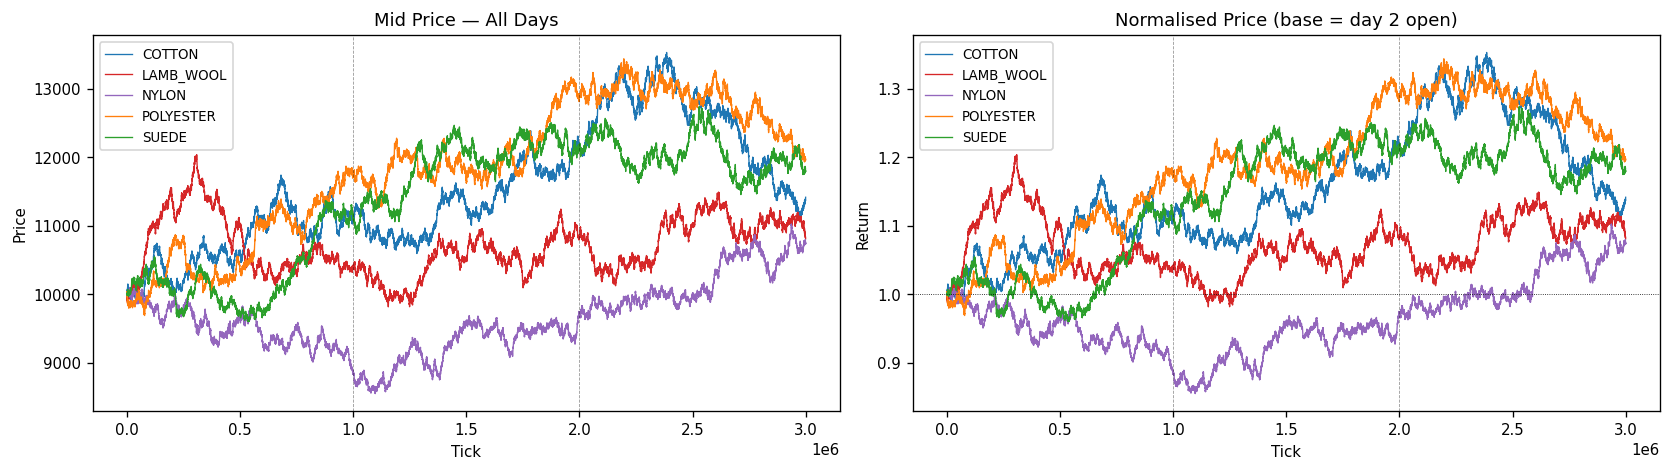

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Absolute prices
ax = axes[0]
for prod in PRODUCTS:
    p = pods[pods['product'] == prod]
    ax.plot(p['t'], p['mid_price'], lw=0.8, label=SHORT[prod], color=COLORS[prod])
for day in [3, 4]:
    ax.axvline((day - 2) * 1_000_000, color='k', lw=0.5, ls='--', alpha=0.4)
ax.set_title('Mid Price — All Days')
ax.set_xlabel('Tick')
ax.legend(fontsize=8)
ax.set_ylabel('Price')

# Normalised (start = 1.0)
ax = axes[1]
for prod in PRODUCTS:
    p = pods[pods['product'] == prod].copy()
    p['norm'] = p['mid_price'] / p['mid_price'].iloc[0]
    ax.plot(p['t'], p['norm'], lw=0.8, label=SHORT[prod], color=COLORS[prod])
for day in [3, 4]:
    ax.axvline((day - 2) * 1_000_000, color='k', lw=0.5, ls='--', alpha=0.4)
ax.axhline(1.0, color='k', lw=0.5, ls=':')
ax.set_title('Normalised Price (base = day 2 open)')
ax.set_xlabel('Tick')
ax.legend(fontsize=8)
ax.set_ylabel('Return')

plt.tight_layout()
plt.show()

## 2. Day-by-Day OLS Slope (Trend Strength)

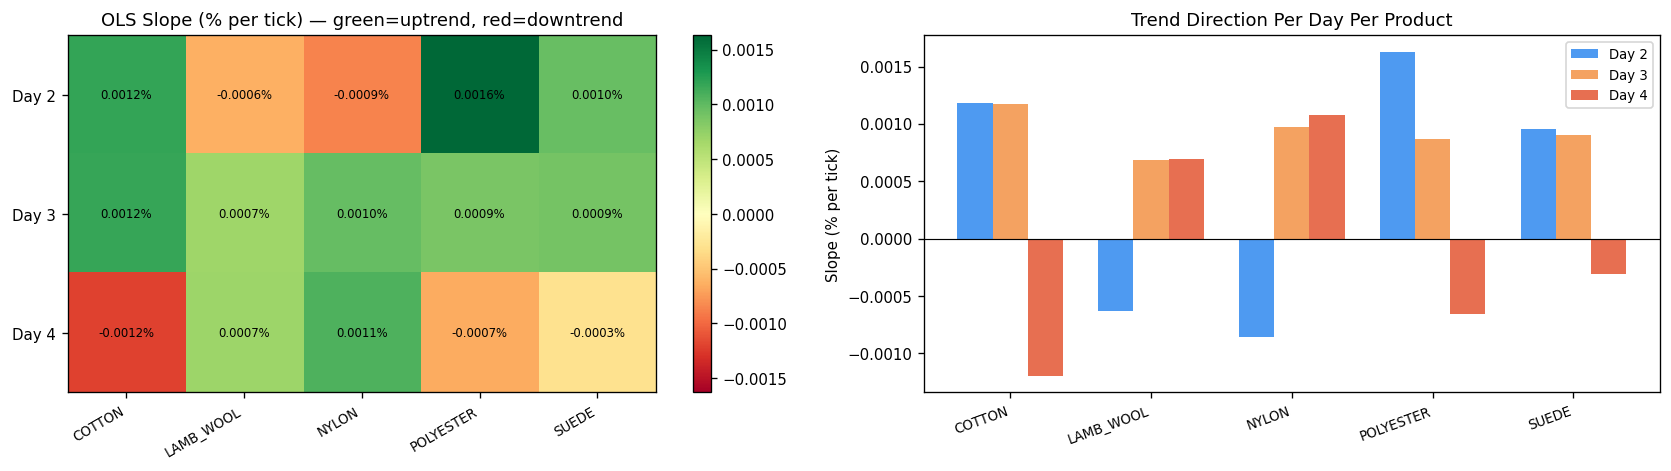

KEY INSIGHT: COTTON, POLYESTER, SUEDE flip to NEGATIVE slope on Day 4.
These are the products our TREND_HOLD strategy holds long — risk of reversal loss.


In [4]:
slope_data = {}
for prod in PRODUCTS:
    slopes = []
    for day in [2, 3, 4]:
        p = pods[(pods['product'] == prod) & (pods['day'] == day)]['mid_price'].values
        x = np.arange(len(p))
        slope = np.polyfit(x, p, 1)[0]
        slopes.append(100 * slope / p.mean())  # % per tick
    slope_data[SHORT[prod]] = slopes

df_slopes = pd.DataFrame(slope_data, index=['Day 2', 'Day 3', 'Day 4'])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Heatmap
ax = axes[0]
vmax = df_slopes.abs().values.max()
im = ax.imshow(df_slopes.values, cmap='RdYlGn', vmin=-vmax, vmax=vmax, aspect='auto')
ax.set_xticks(range(len(df_slopes.columns)))
ax.set_xticklabels(df_slopes.columns, rotation=30, ha='right', fontsize=8)
ax.set_yticks(range(3))
ax.set_yticklabels(['Day 2', 'Day 3', 'Day 4'])
for i in range(3):
    for j in range(len(df_slopes.columns)):
        ax.text(j, i, f'{df_slopes.values[i,j]:.4f}%', ha='center', va='center', fontsize=7)
plt.colorbar(im, ax=ax)
ax.set_title('OLS Slope (% per tick) — green=uptrend, red=downtrend')

# Bar chart
ax = axes[1]
x = np.arange(len(PRODUCTS))
w = 0.25
day_colors = ['#4e9af1', '#f4a261', '#e76f51']
for i, (day_label, dc) in enumerate(zip(['Day 2', 'Day 3', 'Day 4'], day_colors)):
    vals = df_slopes.loc[day_label].values
    bars = ax.bar(x + i*w, vals, w, label=day_label, color=dc)
ax.axhline(0, color='k', lw=0.7)
ax.set_xticks(x + w)
ax.set_xticklabels([SHORT[p] for p in PRODUCTS], rotation=20, ha='right', fontsize=8)
ax.set_ylabel('Slope (% per tick)')
ax.set_title('Trend Direction Per Day Per Product')
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

print('KEY INSIGHT: COTTON, POLYESTER, SUEDE flip to NEGATIVE slope on Day 4.')
print('These are the products our TREND_HOLD strategy holds long — risk of reversal loss.')

## 3. Rolling Volatility (Intraday Risk)

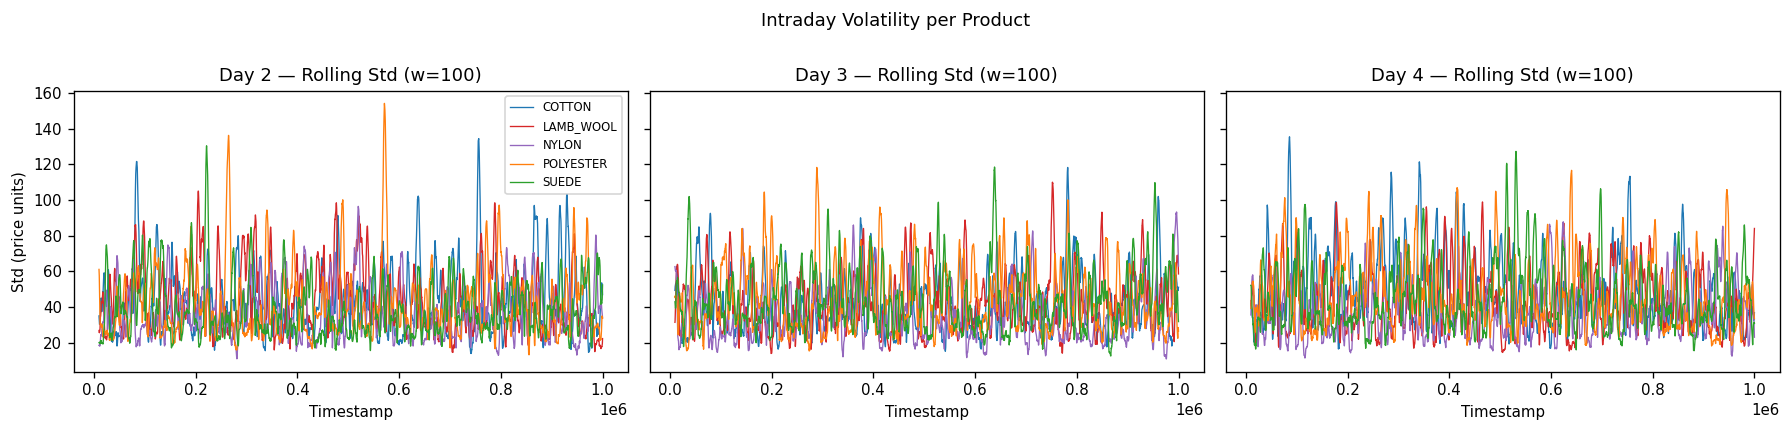

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
WINDOW = 100

for ax, day in zip(axes, [2, 3, 4]):
    for prod in PRODUCTS:
        p = pods[(pods['product'] == prod) & (pods['day'] == day)]
        roll_std = p['mid_price'].rolling(WINDOW).std()
        ax.plot(p['timestamp'], roll_std, lw=0.8, label=SHORT[prod], color=COLORS[prod])
    ax.set_title(f'Day {day} — Rolling Std (w={WINDOW})')
    ax.set_xlabel('Timestamp')
    if day == 2:
        ax.set_ylabel('Std (price units)')
        ax.legend(fontsize=7)

plt.suptitle('Intraday Volatility per Product', y=1.01)
plt.tight_layout()
plt.show()

## 4. Correlation Structure

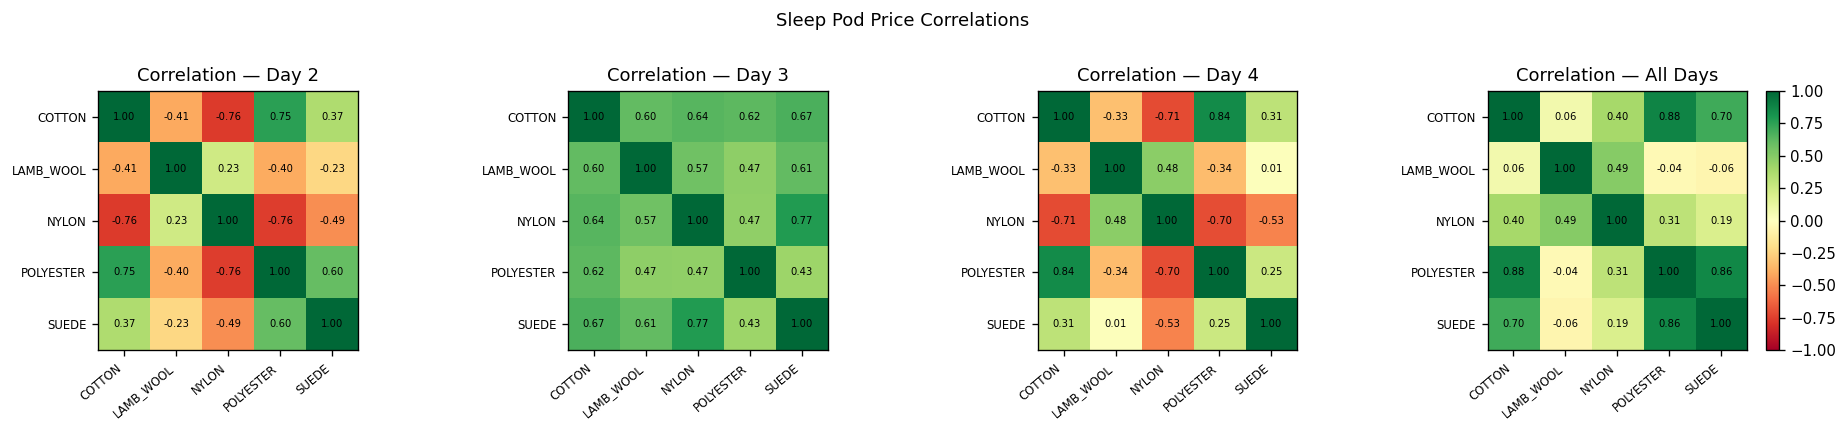

KEY: COTTON-POLYESTER-SUEDE form a tight cluster (corr 0.70-0.88).
LAMB_WOOL and NYLON are weakly correlated with the cluster.


In [15]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
labels = [SHORT[p] for p in PRODUCTS]

for ax, (day_label, subset) in zip(axes[:3], [('Day 2', 2), ('Day 3', 3), ('Day 4', 4)]):
    sub = pivot[pivot['day'] == subset][PRODUCTS].rename(columns=SHORT)
    corr = sub.corr()
    im = ax.imshow(corr.values, cmap='RdYlGn', vmin=-1, vmax=1)
    ax.set_xticks(range(5))
    ax.set_xticklabels(labels, rotation=40, ha='right', fontsize=7)
    ax.set_yticks(range(5))
    ax.set_yticklabels(labels, fontsize=7)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f'{corr.values[i,j]:.2f}', ha='center', va='center', fontsize=6)
    ax.set_title(f'Correlation — {day_label}')

# All days
ax = axes[3]
corr_all = pivot[PRODUCTS].rename(columns=SHORT).corr()
im = ax.imshow(corr_all.values, cmap='RdYlGn', vmin=-1, vmax=1)
ax.set_xticks(range(5))
ax.set_xticklabels(labels, rotation=40, ha='right', fontsize=7)
ax.set_yticks(range(5))
ax.set_yticklabels(labels, fontsize=7)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f'{corr_all.values[i,j]:.2f}', ha='center', va='center', fontsize=6)
ax.set_title('Correlation — All Days')
plt.colorbar(im, ax=axes[3])

plt.suptitle('Sleep Pod Price Correlations', y=1.01)
plt.tight_layout()
plt.show()

print('KEY: COTTON-POLYESTER-SUEDE form a tight cluster (corr 0.70-0.88).')
print('LAMB_WOOL and NYLON are weakly correlated with the cluster.')

## 5. Pairwise Spreads — Is Anything Mean-Reverting?

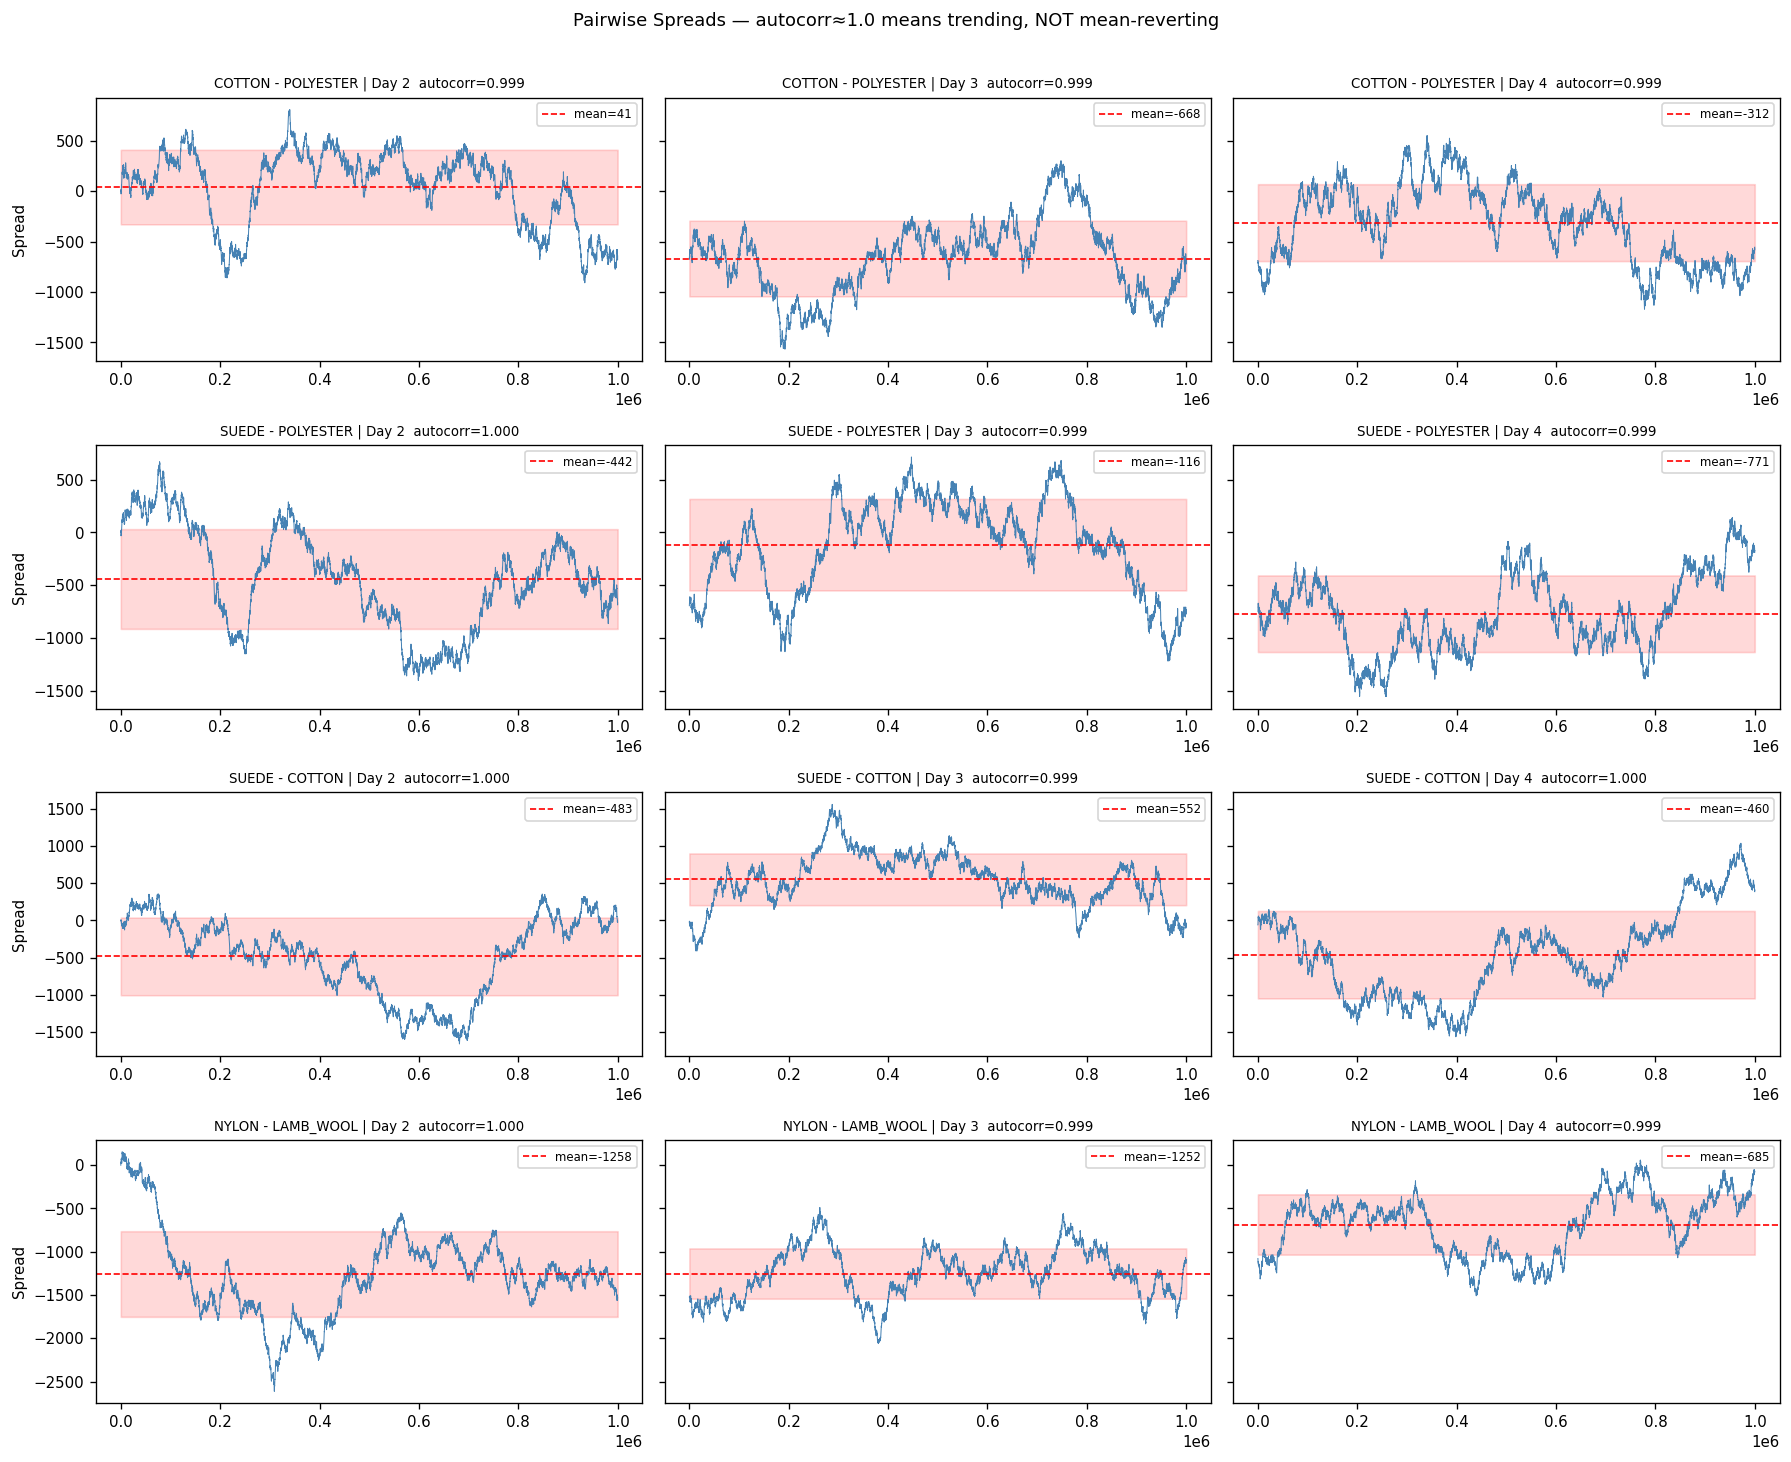

ALL spreads have autocorr ~0.999 — they are random walks with drift.
No pair is mean-reverting. DO NOT run z-score MR on these pairs.


In [7]:
PAIRS = [
    ('SLEEP_POD_COTTON',    'SLEEP_POD_POLYESTER'),
    ('SLEEP_POD_SUEDE',     'SLEEP_POD_POLYESTER'),
    ('SLEEP_POD_SUEDE',     'SLEEP_POD_COTTON'),
    ('SLEEP_POD_NYLON',     'SLEEP_POD_LAMB_WOOL'),
]

fig, axes = plt.subplots(len(PAIRS), 3, figsize=(15, 3 * len(PAIRS)), sharey='row')

for row, (a, b) in enumerate(PAIRS):
    pair_label = f'{SHORT[a]} - {SHORT[b]}'
    for col, day in enumerate([2, 3, 4]):
        sub = pivot[pivot['day'] == day]
        diff = sub[a] - sub[b]
        ax = axes[row][col]
        ax.plot(sub['timestamp'], diff.values, lw=0.6, color='steelblue')
        ax.axhline(diff.mean(), color='red', lw=1, ls='--', label=f'mean={diff.mean():.0f}')
        ax.fill_between(sub['timestamp'],
                        diff.mean() - diff.std(), diff.mean() + diff.std(),
                        alpha=0.15, color='red')
        ax.set_title(f'{pair_label} | Day {day}  autocorr={diff.autocorr():.3f}', fontsize=8)
        if col == 0:
            ax.set_ylabel('Spread')
        ax.legend(fontsize=7)

plt.suptitle('Pairwise Spreads — autocorr≈1.0 means trending, NOT mean-reverting', y=1.01)
plt.tight_layout()
plt.show()

print('ALL spreads have autocorr ~0.999 — they are random walks with drift.')
print('No pair is mean-reverting. DO NOT run z-score MR on these pairs.')

## 6. Bid-Ask Spread Over Time (MM Profitability)

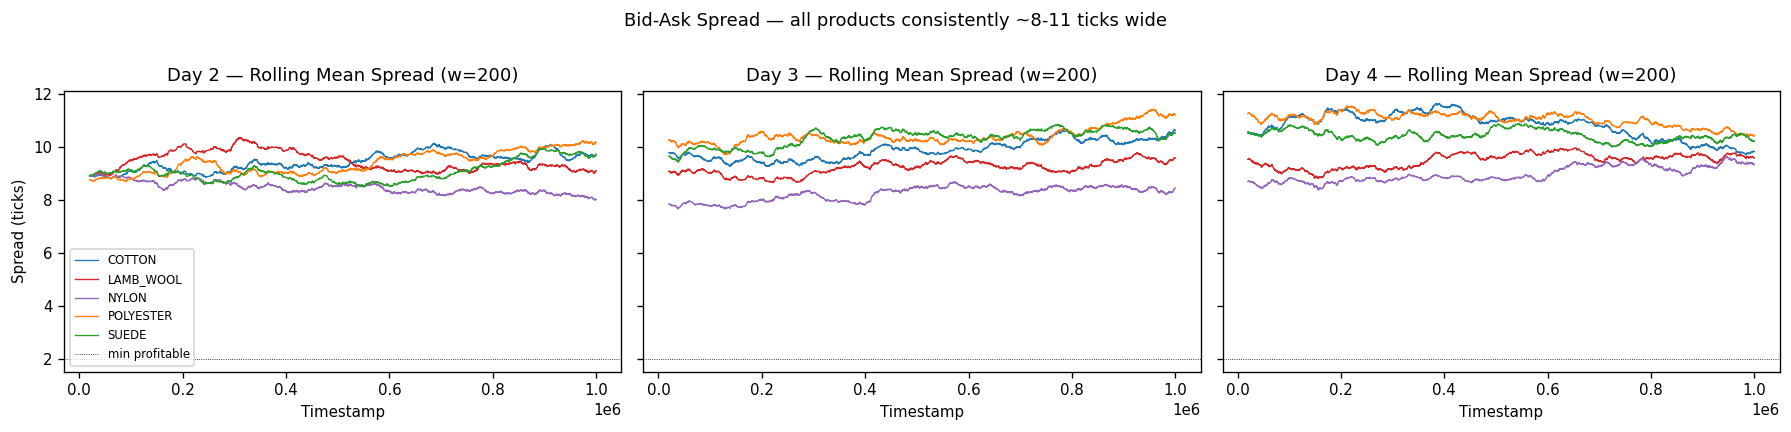

                          mean   std
product             day             
SLEEP_POD_COTTON    2     9.44  0.98
                    3     9.90  1.07
                    4    10.81  1.20
SLEEP_POD_LAMB_WOOL 2     9.46  1.01
                    3     9.22  0.99
                    4     9.51  1.02
SLEEP_POD_NYLON     2     8.48  0.89
                    3     8.24  0.91
                    4     8.98  0.97
SLEEP_POD_POLYESTER 2     9.40  1.01
                    3    10.43  1.12
                    4    11.05  1.15
SLEEP_POD_SUEDE     2     9.06  0.95
                    3    10.35  1.09
                    4    10.44  1.09

NYLON has the tightest spread (~8.5). POLYESTER/SUEDE widen in days 3-4 as price rises.


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)

for ax, day in zip(axes, [2, 3, 4]):
    for prod in PRODUCTS:
        p = pods[(pods['product'] == prod) & (pods['day'] == day)]
        roll_spread = p['spread'].rolling(200).mean()
        ax.plot(p['timestamp'], roll_spread, lw=0.8, label=SHORT[prod], color=COLORS[prod])
    ax.set_title(f'Day {day} — Rolling Mean Spread (w=200)')
    ax.set_xlabel('Timestamp')
    ax.axhline(2, color='k', lw=0.5, ls=':', label='min profitable')
    if day == 2:
        ax.set_ylabel('Spread (ticks)')
        ax.legend(fontsize=7)

plt.suptitle('Bid-Ask Spread — all products consistently ~8-11 ticks wide', y=1.01)
plt.tight_layout()
plt.show()

# Summary table
summary = pods.groupby(['product', 'day'])['spread'].agg(['mean', 'std']).round(2)
print(summary.to_string())
print()
print('NYLON has the tightest spread (~8.5). POLYESTER/SUEDE widen in days 3-4 as price rises.')

## 7. Momentum Signal — Short EMA vs Long EMA Crossover

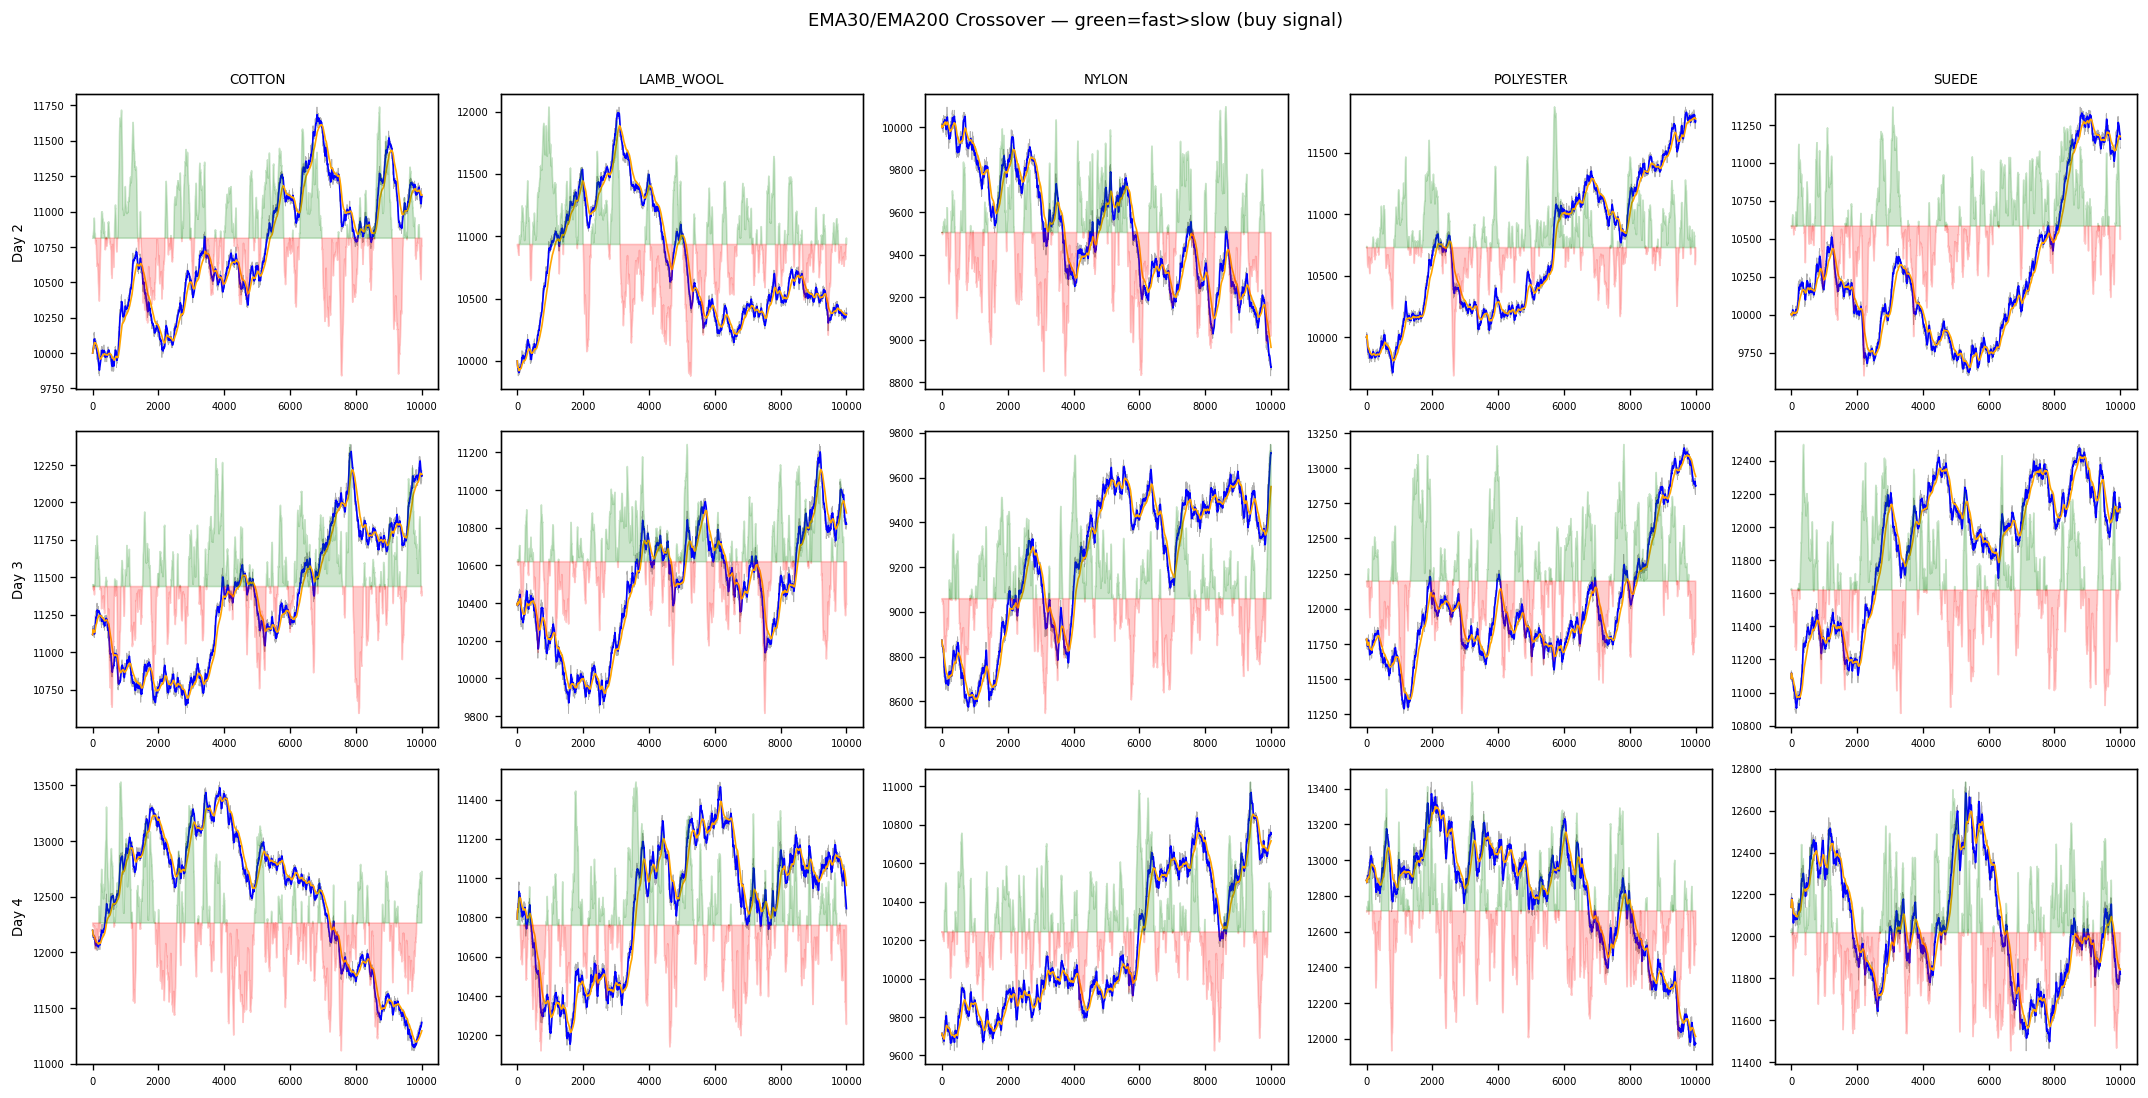

In [9]:
fig, axes = plt.subplots(3, 5, figsize=(18, 9), sharex=False)

FAST, SLOW = 30, 200

for col, prod in enumerate(PRODUCTS):
    for row, day in enumerate([2, 3, 4]):
        p = pods[(pods['product'] == prod) & (pods['day'] == day)].copy()
        p = p.reset_index(drop=True)
        p['ema_fast'] = p['mid_price'].ewm(span=FAST).mean()
        p['ema_slow'] = p['mid_price'].ewm(span=SLOW).mean()
        p['signal']   = p['ema_fast'] - p['ema_slow']

        ax = axes[row][col]
        ax.plot(p.index, p['mid_price'], lw=0.5, color='gray', alpha=0.6)
        ax.plot(p.index, p['ema_fast'],  lw=1,   color='blue',  label=f'EMA{FAST}')
        ax.plot(p.index, p['ema_slow'],  lw=1,   color='orange', label=f'EMA{SLOW}')

        # Shade signal direction
        ax2 = ax.twinx()
        ax2.fill_between(p.index, 0, p['signal'],
                         where=p['signal'] > 0, alpha=0.2, color='green')
        ax2.fill_between(p.index, 0, p['signal'],
                         where=p['signal'] < 0, alpha=0.2, color='red')
        ax2.set_yticks([])

        if row == 0:
            ax.set_title(SHORT[prod], fontsize=8)
        if col == 0:
            ax.set_ylabel(f'Day {day}', fontsize=8)
        ax.tick_params(labelsize=6)

plt.suptitle(f'EMA{FAST}/EMA{SLOW} Crossover — green=fast>slow (buy signal)', y=1.01)
plt.tight_layout()
plt.show()

## 8. Day 4 Reversal — When Does It Start?

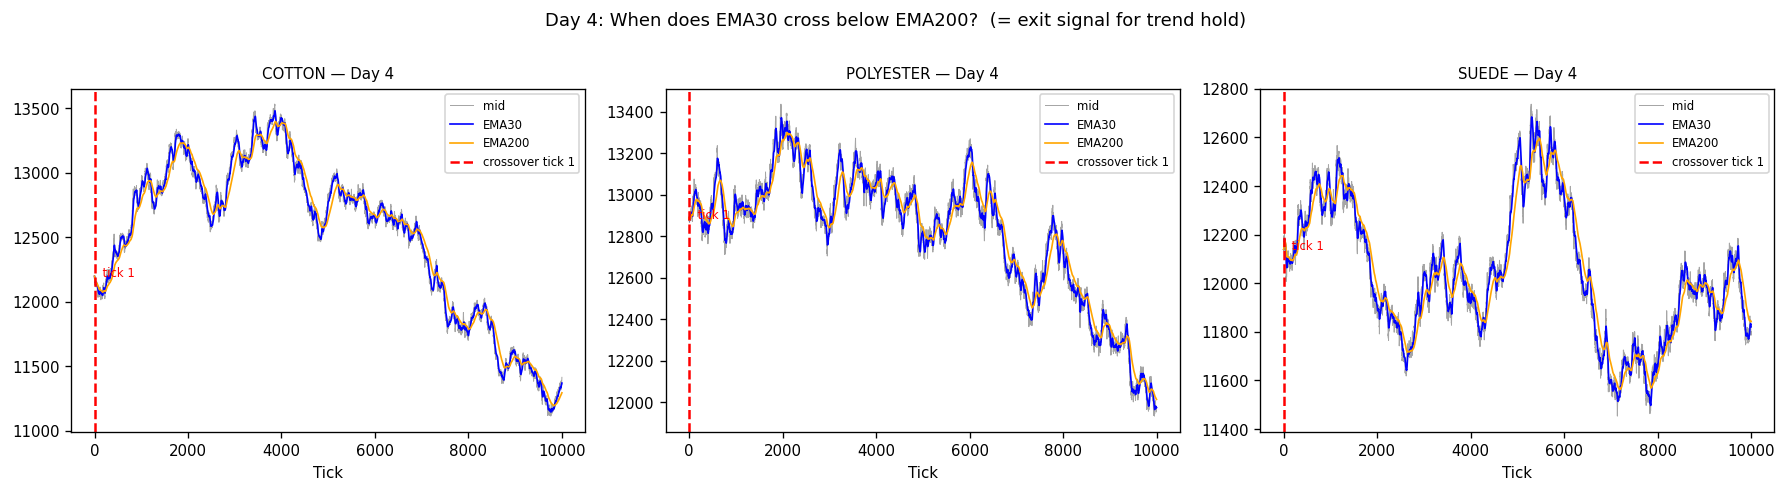

COTTON      : crossover at tick 1, price 12197, peak 13530, drawdown -9.8%
POLYESTER   : crossover at tick 1, price 12884, peak 13437, drawdown -4.1%
SUEDE       : crossover at tick 1, price 12138, peak 12736, drawdown -4.7%


In [10]:
# For TREND_HOLD products that reversed on day 4, find where the EMA crossover flips
TREND_PRODS = ['SLEEP_POD_COTTON', 'SLEEP_POD_POLYESTER', 'SLEEP_POD_SUEDE']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, prod in zip(axes, TREND_PRODS):
    p = pods[(pods['product'] == prod) & (pods['day'] == 4)].copy().reset_index(drop=True)
    p['ema30']  = p['mid_price'].ewm(span=30).mean()
    p['ema200'] = p['mid_price'].ewm(span=200).mean()
    p['signal'] = p['ema30'] - p['ema200']

    # Find first crossover (signal goes negative)
    cross_idx = p[p['signal'] < 0].index.min() if (p['signal'] < 0).any() else None

    ax.plot(p.index, p['mid_price'],  lw=0.6, color='gray',   alpha=0.7, label='mid')
    ax.plot(p.index, p['ema30'],      lw=1,   color='blue',   label='EMA30')
    ax.plot(p.index, p['ema200'],     lw=1,   color='orange', label='EMA200')

    if cross_idx is not None:
        ax.axvline(cross_idx, color='red', lw=1.5, ls='--',
                   label=f'crossover tick {cross_idx}')
        ax.text(cross_idx + 10, p['mid_price'].iloc[cross_idx],
                f'  tick {cross_idx}', fontsize=7, color='red')

    ax.set_title(f'{SHORT[prod]} — Day 4', fontsize=9)
    ax.legend(fontsize=7)
    ax.set_xlabel('Tick')

plt.suptitle('Day 4: When does EMA30 cross below EMA200?  (= exit signal for trend hold)',
             y=1.01)
plt.tight_layout()
plt.show()

for prod in TREND_PRODS:
    p = pods[(pods['product'] == prod) & (pods['day'] == 4)].copy().reset_index(drop=True)
    p['ema30']  = p['mid_price'].ewm(span=30).mean()
    p['ema200'] = p['mid_price'].ewm(span=200).mean()
    p['signal'] = p['ema30'] - p['ema200']
    cross = p[p['signal'] < 0].index.min()
    price_at_cross = p['mid_price'].iloc[cross] if cross is not None else None
    price_peak = p['mid_price'].max()
    drawdown = (price_at_cross - price_peak) / price_peak * 100 if cross is not None else None
    print(f'{SHORT[prod]:12s}: crossover at tick {cross}, price {price_at_cross:.0f}, peak {price_peak:.0f}, drawdown {drawdown:.1f}%')

## 9. Summary Insights

In [11]:
print('=== SLEEP POD INSIGHTS ===')
print()
print('TREND STRUCTURE')
print('  COTTON, POLYESTER, SUEDE: strong uptrend day 2+3, REVERSE on day 4')
print('  NYLON: mild uptrend all 3 days (safest to hold)')
print('  LAMB_WOOL: mixed trend, disabled — correct decision')
print()
print('CORRELATION CLUSTERS')
print('  Cluster A (corr 0.70-0.88): COTTON, POLYESTER, SUEDE')
print('  Cluster B (weakly linked): NYLON, LAMB_WOOL')
print('  No pair is mean-reverting (autocorr ≈ 0.999 on all spreads)')
print()
print('MARKET MAKING')
print('  All spreads ~8-11 ticks — well above minimum for profitable MM')
print('  NYLON tightest (~8.5 ticks), POLYESTER/SUEDE widest in late days')
print('  Depth consistent at ~11 units L1 on both sides')
print()
print('STRATEGY IMPLICATIONS')
print('  1. TREND_HOLD for POLYESTER, SUEDE, COTTON is profitable day 2+3')
print('     but needs a stop/exit for day 4 reversal')
print('  2. EMA30/EMA200 crossover gives reversal warning early in day 4')
print('     — could use this to exit TREND_HOLD position')
print('  3. NYLON: pure MM is best (weak trend, tight spread)')
print('  4. DO NOT run z-score MR on any pair — all spreads are trending')

=== SLEEP POD INSIGHTS ===

TREND STRUCTURE
  COTTON, POLYESTER, SUEDE: strong uptrend day 2+3, REVERSE on day 4
  NYLON: mild uptrend all 3 days (safest to hold)
  LAMB_WOOL: mixed trend, disabled — correct decision

CORRELATION CLUSTERS
  Cluster A (corr 0.70-0.88): COTTON, POLYESTER, SUEDE
  Cluster B (weakly linked): NYLON, LAMB_WOOL
  No pair is mean-reverting (autocorr ≈ 0.999 on all spreads)

MARKET MAKING
  All spreads ~8-11 ticks — well above minimum for profitable MM
  NYLON tightest (~8.5 ticks), POLYESTER/SUEDE widest in late days
  Depth consistent at ~11 units L1 on both sides

STRATEGY IMPLICATIONS
  1. TREND_HOLD for POLYESTER, SUEDE, COTTON is profitable day 2+3
     but needs a stop/exit for day 4 reversal
  2. EMA30/EMA200 crossover gives reversal warning early in day 4
     — could use this to exit TREND_HOLD position
  3. NYLON: pure MM is best (weak trend, tight spread)
  4. DO NOT run z-score MR on any pair — all spreads are trending


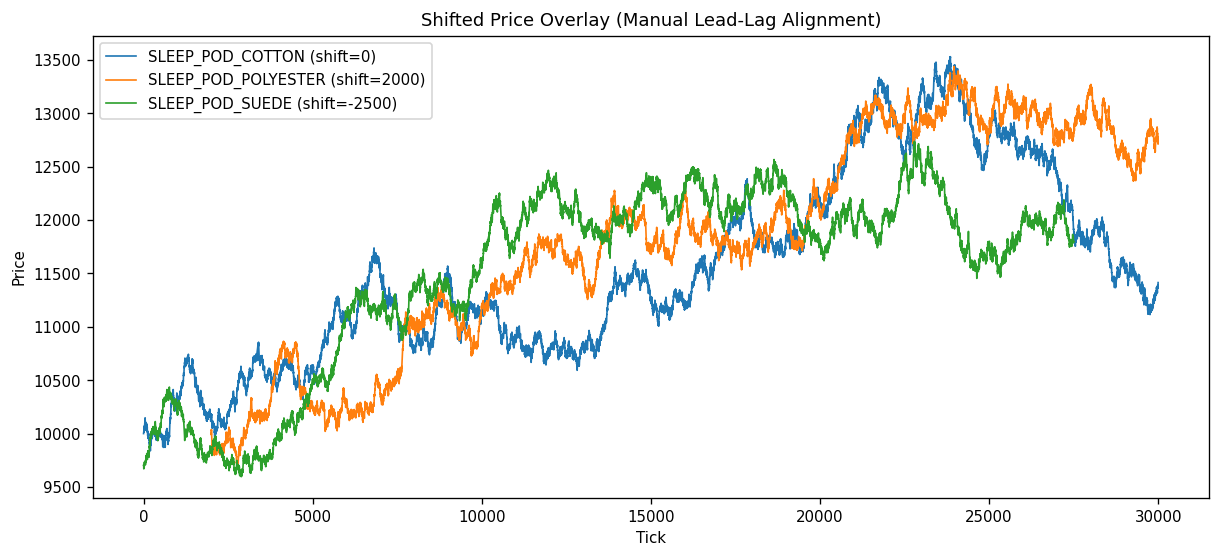

In [24]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# PRODUCTS
# -----------------------------
products = [
    'SLEEP_POD_COTTON',
    'SLEEP_POD_POLYESTER',
    'SLEEP_POD_SUEDE'
]

# -----------------------------
# SHIFT CONTROLS (EDIT HERE)
# positive = shift right (delay)
# negative = shift left (lead)
# -----------------------------
SHIFT = {
    'SLEEP_POD_COTTON': 0,
    'SLEEP_POD_POLYESTER': 2000,   # <-- example: polyester leads cotton
    'SLEEP_POD_SUEDE': -2500
}

# -----------------------------
# LOAD + ALIGN
# -----------------------------
series = {}

min_len = float('inf')

for prod in products:
    df = pods[pods['product'] == prod].copy()
    df = df.sort_values('t').reset_index(drop=True)

    series[prod] = df['mid_price'].values
    min_len = min(min_len, len(df))

# truncate
for k in series:
    series[k] = series[k][:min_len]

# -----------------------------
# PLOT WITH SHIFT
# -----------------------------
plt.figure(figsize=(12,5))

for prod in products:
    shift = SHIFT[prod]
    data = series[prod]

    # apply shift
    if shift > 0:
        shifted = np.concatenate([np.full(shift, np.nan), data[:-shift]])
    elif shift < 0:
        shifted = np.concatenate([data[-shift:], np.full(-shift, np.nan)])
    else:
        shifted = data

    plt.plot(shifted, label=f"{prod} (shift={shift})", lw=1)

plt.title("Shifted Price Overlay (Manual Lead-Lag Alignment)")
plt.xlabel("Tick")
plt.ylabel("Price")
plt.legend()
plt.show()

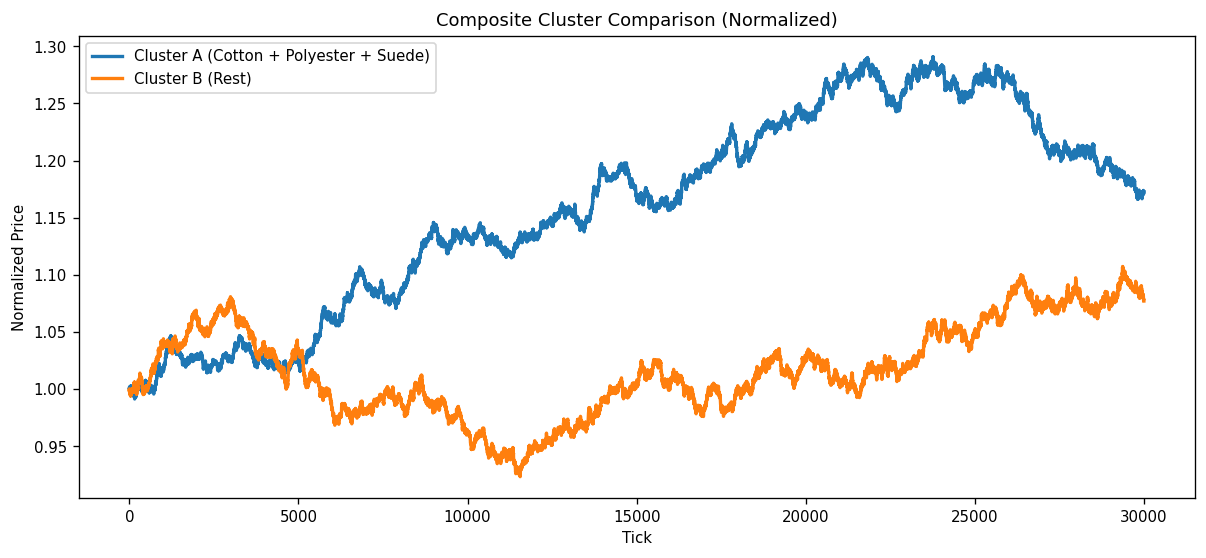

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# DEFINE CLUSTER A (your hypothesis group)
# -----------------------------
cluster_a = [
    'SLEEP_POD_COTTON',
    'SLEEP_POD_POLYESTER',
    'SLEEP_POD_SUEDE'
]

# -----------------------------
# DEFINE CLUSTER B (rest of Sleep Pod)
# -----------------------------
cluster_b = [
    'SLEEP_POD_LAMB_WOOL',
    'SLEEP_POD_NYLON'
]

# -----------------------------
# helper: extract normalized price
# -----------------------------
def get_norm_series(prod):
    df = pods[pods['product'] == prod].copy()
    df = df.sort_values('t').reset_index(drop=True)
    return df['mid_price'].values / df['mid_price'].iloc[0]

# -----------------------------
# align lengths
# -----------------------------
series_a = [get_norm_series(p) for p in cluster_a]
series_b = [get_norm_series(p) for p in cluster_b]

min_len = min(min(len(s) for s in series_a),
              min(len(s) for s in series_b))

series_a = [s[:min_len] for s in series_a]
series_b = [s[:min_len] for s in series_b]

# -----------------------------
# build composites (equal weight)
# -----------------------------
comp_a = np.mean(np.vstack(series_a), axis=0)
comp_b = np.mean(np.vstack(series_b), axis=0)

# -----------------------------
# plot
# -----------------------------
plt.figure(figsize=(12,5))

plt.plot(comp_a, label="Cluster A (Cotton + Polyester + Suede)", lw=2)
plt.plot(comp_b, label="Cluster B (Rest)", lw=2)

plt.title("Composite Cluster Comparison (Normalized)")
plt.xlabel("Tick")
plt.ylabel("Normalized Price")
plt.legend()
plt.show()

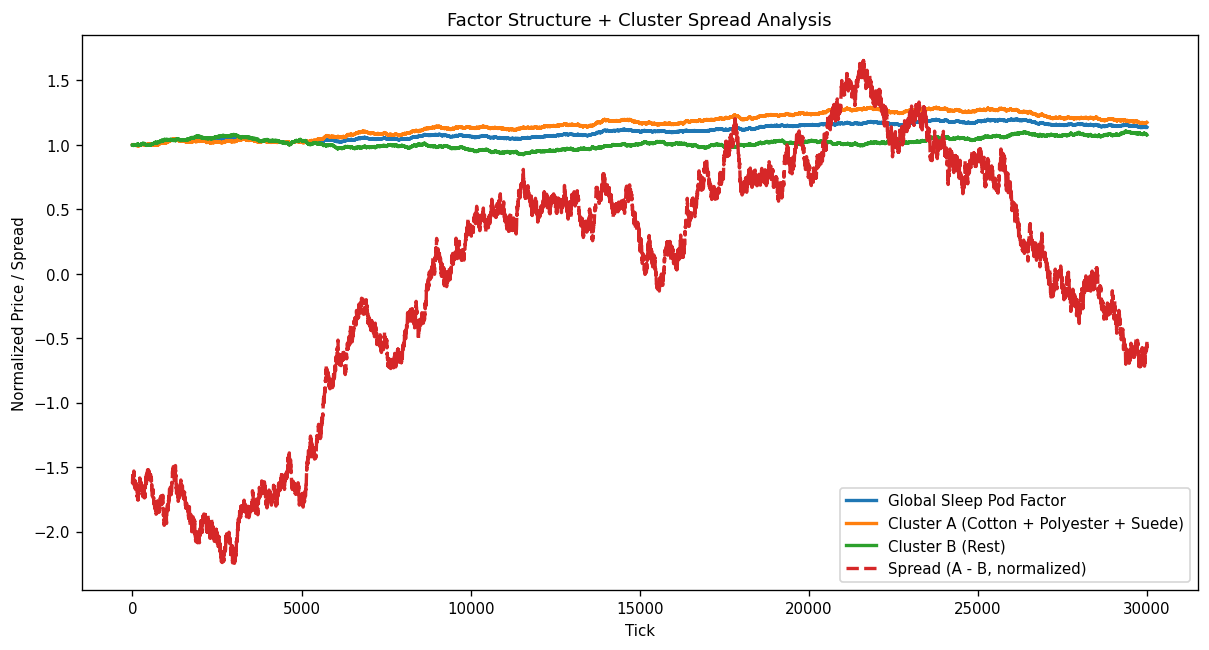

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# CLUSTER A (your hypothesis group)
# -----------------------------
cluster_a = [
    'SLEEP_POD_COTTON',
    'SLEEP_POD_POLYESTER',
    'SLEEP_POD_SUEDE'
]

# -----------------------------
# CLUSTER B (rest of Sleep Pods)
# -----------------------------
cluster_b = [
    'SLEEP_POD_LAMB_WOOL',
    'SLEEP_POD_NYLON'
]

# -----------------------------
# ALL Sleep Pod products (global factor)
# -----------------------------
all_products = cluster_a + cluster_b

# -----------------------------
# helper
# -----------------------------
def get_norm(prod):
    df = pods[pods['product'] == prod].copy()
    df = df.sort_values('t').reset_index(drop=True)
    return df['mid_price'].values / df['mid_price'].iloc[0]

# -----------------------------
# load series
# -----------------------------
series_a = [get_norm(p) for p in cluster_a]
series_b = [get_norm(p) for p in cluster_b]
series_all = [get_norm(p) for p in all_products]

# align lengths
min_len = min(
    min(len(s) for s in series_a),
    min(len(s) for s in series_b),
    min(len(s) for s in series_all),
)

series_a = [s[:min_len] for s in series_a]
series_b = [s[:min_len] for s in series_b]
series_all = [s[:min_len] for s in series_all]

# -----------------------------
# composites
# -----------------------------
comp_a = np.mean(np.vstack(series_a), axis=0)
comp_b = np.mean(np.vstack(series_b), axis=0)
comp_all = np.mean(np.vstack(series_all), axis=0)

spread = comp_a - comp_b

# normalize spread for visibility
spread = (spread - np.mean(spread)) / (np.std(spread) + 1e-8)

# -----------------------------
# plot
# -----------------------------
plt.figure(figsize=(12,6))

plt.plot(comp_all, label="Global Sleep Pod Factor", lw=2)
plt.plot(comp_a, label="Cluster A (Cotton + Polyester + Suede)", lw=2)
plt.plot(comp_b, label="Cluster B (Rest)", lw=2)
plt.plot(spread, label="Spread (A - B, normalized)", lw=2, linestyle='--')

plt.title("Factor Structure + Cluster Spread Analysis")
plt.xlabel("Tick")
plt.ylabel("Normalized Price / Spread")
plt.legend()
plt.show()

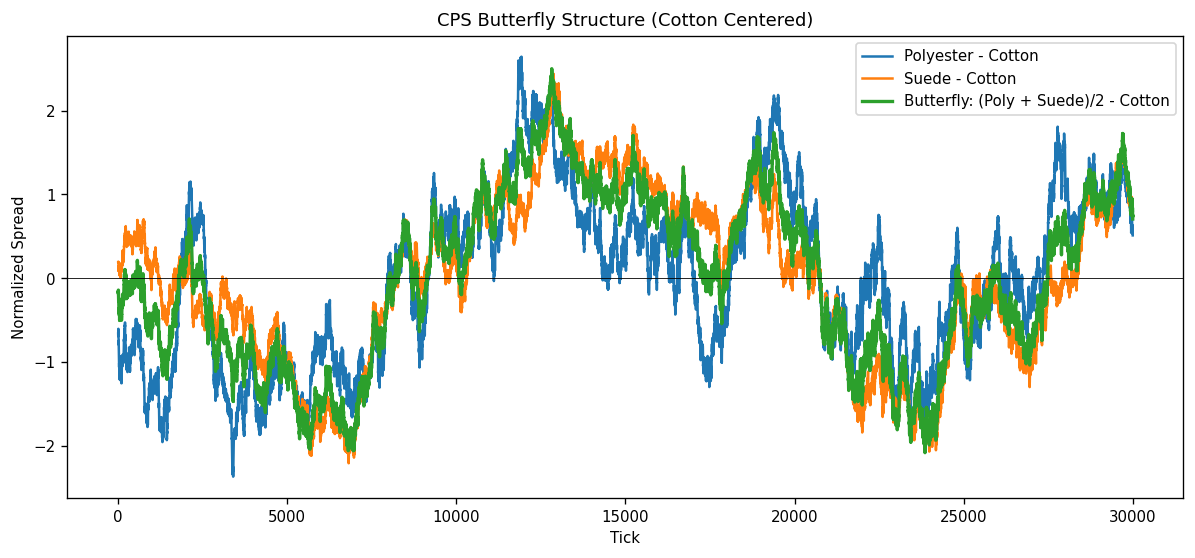

In [25]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# PRODUCTS
# -----------------------------
cotton = 'SLEEP_POD_COTTON'
poly   = 'SLEEP_POD_POLYESTER'
suede  = 'SLEEP_POD_SUEDE'

def get_series(prod):
    df = pods[pods['product'] == prod].copy()
    df = df.sort_values('t').reset_index(drop=True)
    return df['mid_price'].values

# -----------------------------
# LOAD
# -----------------------------
c = get_series(cotton)
p = get_series(poly)
s = get_series(suede)

# align lengths
n = min(len(c), len(p), len(s))
c, p, s = c[:n], p[:n], s[:n]

# -----------------------------
# BUTTERFLY LEGS
# -----------------------------
spread_poly  = p - c
spread_suede = s - c

# symmetric butterfly (classic structure)
butterfly = (p + s) / 2 - c

# normalize for comparability
def norm(x):
    return (x - np.mean(x)) / (np.std(x) + 1e-8)

spread_poly  = norm(spread_poly)
spread_suede = norm(spread_suede)
butterfly    = norm(butterfly)

# -----------------------------
# PLOT
# -----------------------------
plt.figure(figsize=(12,5))

plt.plot(spread_poly, label="Polyester - Cotton", lw=1.5)
plt.plot(spread_suede, label="Suede - Cotton", lw=1.5)
plt.plot(butterfly, label="Butterfly: (Poly + Suede)/2 - Cotton", lw=2)

plt.axhline(0, color='black', lw=0.5)
plt.title("CPS Butterfly Structure (Cotton Centered)")
plt.xlabel("Tick")
plt.ylabel("Normalized Spread")
plt.legend()
plt.show()

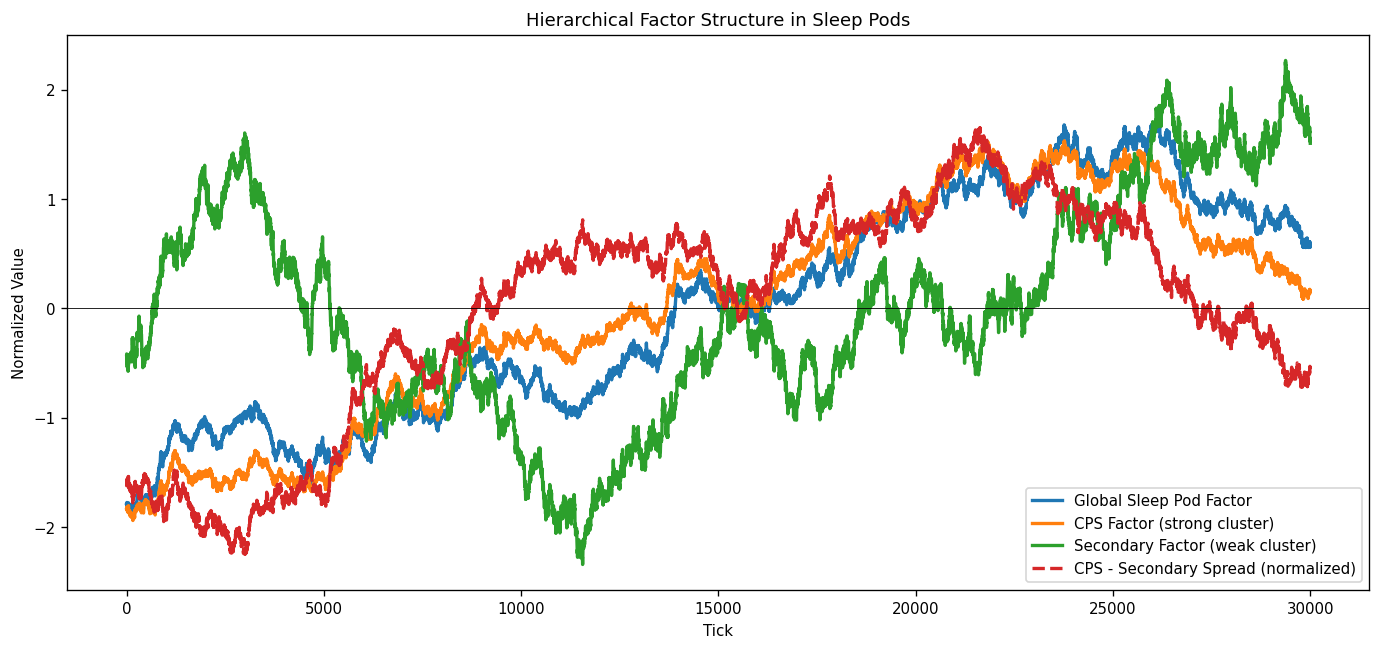

In [30]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# helper
# -----------------------------
def get_series(prod):
    df = pods[pods['product'] == prod].copy()
    if len(df) == 0:
        print(f"[WARN] missing {prod}")
        return None
    df = df.sort_values('t')
    return df['mid_price'].values


def norm(x):
    return (x - np.mean(x)) / (np.std(x) + 1e-8)


def align(series_list):
    min_len = min(len(s) for s in series_list)
    return [s[:min_len] for s in series_list]

# -----------------------------
# PRODUCTS
# -----------------------------
cps = [
    "SLEEP_POD_COTTON",
    "SLEEP_POD_POLYESTER",
    "SLEEP_POD_SUEDE"
]

secondary = [
    "SLEEP_POD_LAMB_WOOL",
    "SLEEP_POD_NYLON"
]

all_pods = cps + secondary

# -----------------------------
# LOAD
# -----------------------------
cps_s = [get_series(p) for p in cps]
sec_s = [get_series(p) for p in secondary]
all_s = [get_series(p) for p in all_pods]

# remove missing
cps_s = [s for s in cps_s if s is not None]
sec_s = [s for s in sec_s if s is not None]
all_s = [s for s in all_s if s is not None]

# align
cps_s = align(cps_s)
sec_s = align(sec_s)
all_s = align(all_s)

# -----------------------------
# FACTORS
# -----------------------------
F_cps = np.mean(np.vstack(cps_s), axis=0)
F_sec = np.mean(np.vstack(sec_s), axis=0)
F_all = np.mean(np.vstack(all_s), axis=0)

# -----------------------------
# SPREAD
# -----------------------------
spread = norm(F_cps - F_sec)

# normalize factors for visual comparison
F_cps = norm(F_cps)
F_sec = norm(F_sec)
F_all = norm(F_all)

# -----------------------------
# PLOT
# -----------------------------
plt.figure(figsize=(14,6))

plt.plot(F_all, label="Global Sleep Pod Factor", linewidth=2)
plt.plot(F_cps, label="CPS Factor (strong cluster)", linewidth=2)
plt.plot(F_sec, label="Secondary Factor (weak cluster)", linewidth=2)
plt.plot(spread, label="CPS - Secondary Spread (normalized)", linewidth=2, linestyle="--")

plt.axhline(0, color="black", linewidth=0.5)

plt.title("Hierarchical Factor Structure in Sleep Pods")
plt.xlabel("Tick")
plt.ylabel("Normalized Value")
plt.legend()
plt.show()

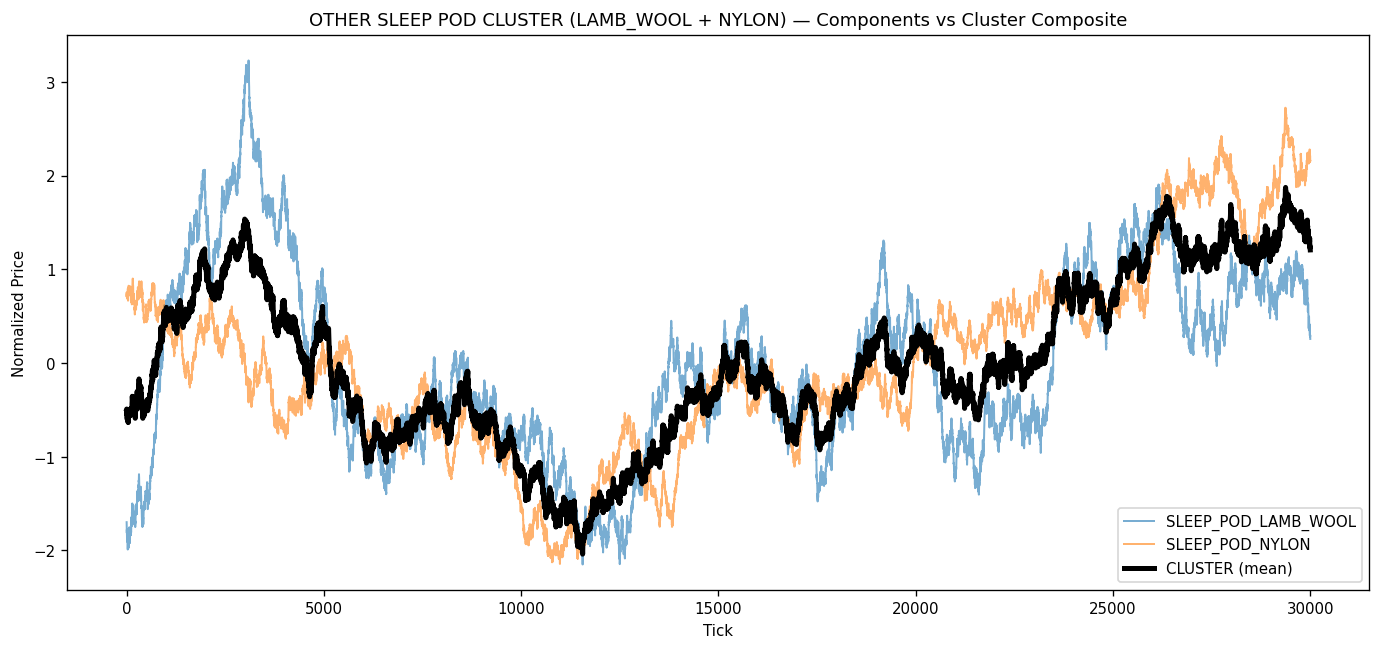

In [29]:
def get_mid_series(pods, product):
    df = pods[pods['product'] == product].copy()
    if len(df) == 0:
        print(f"[WARN] No data for {product}")
        return None
    df = df.sort_values('t')
    return df['mid_price'].values


def normalize(x):
    return (x - np.mean(x)) / (np.std(x) + 1e-8)


def plot_cluster(products, pods, title="Cluster"):
    series = {}

    # load series
    for p in products:
        s = get_mid_series(pods, p)
        if s is not None:
            series[p] = s

    if len(series) == 0:
        print("No valid data found.")
        return

    # align lengths
    min_len = min(len(s) for s in series.values())
    for p in series:
        series[p] = normalize(series[p][:min_len])

    # cluster composite
    cluster = np.mean(np.vstack(list(series.values())), axis=0)

    # -----------------------------
    # PLOT
    # -----------------------------
    plt.figure(figsize=(14,6))

    # individual legs
    for p, s in series.items():
        plt.plot(s, alpha=0.6, linewidth=1.2, label=p)

    # cluster composite
    plt.plot(cluster, linewidth=3, color="black", label="CLUSTER (mean)")

    plt.title(f"{title} — Components vs Cluster Composite")
    plt.xlabel("Tick")
    plt.ylabel("Normalized Price")
    plt.legend()
    plt.show()

plot_cluster(["SLEEP_POD_LAMB_WOOL", "SLEEP_POD_NYLON"], pods, "OTHER SLEEP POD CLUSTER (LAMB_WOOL + NYLON)")